# Homework 4: Decision Tree
Denis Samitov — AI240 18795

This project uses a Decision Tree classifier to predict the loan repayment
result. The target column is result: yes = 1 and no
= 0.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)

df = pd.read_csv("Loans_Dataset.csv")

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (1004, 6)


,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,yes
1,205,10016,395,3044,13660,yes
2,257,10129,109,3251,13746,yes
3,246,10064,324,3137,13771,yes
4,117,10115,496,3094,13822,yes
5,406,10187,166,3068,13827,yes
6,461,10252,172,3062,13947,yes
7,158,10192,144,3469,13963,yes
8,136,10376,230,3223,13965,yes
9,194,10092,626,3083,13995,yes


In [3]:
df.info()
display(df.describe())

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget counts:")
print(df["result"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   initial_payment  1004 non-null   int64 
 1   last_payment     1004 non-null   int64 
 2   credit_score     1004 non-null   int64 
 3   house_number     1004 non-null   int64 
 4   sum              1004 non-null   int64 
 5   result           1004 non-null   object
dtypes: int64(5), object(1)
memory usage: 47.2+ KB


,initial_payment,last_payment,credit_score,house_number,sum
count,1004.000000,1004.000000,1004.000000,1004.000000,1004.000000
mean,294.662351,12473.009960,528.902390,4041.282869,17744.012948
std,115.844218,1442.134231,259.681745,618.431417,9594.659715
min,100.000000,10005.000000,100.000000,3003.000000,13515.000000
25%,195.750000,11213.500000,302.750000,3546.500000,16081.250000
50%,290.000000,12467.000000,518.000000,4046.000000,17383.000000
75%,398.000000,13690.000000,755.000000,4508.750000,18608.250000
max,500.000000,14999.000000,997.000000,9876.000000,246789.000000



Missing values:
initial_payment    0
last_payment       0
credit_score       0
house_number       0
sum                0
result             0
dtype: int64

Duplicate rows: 0

Target counts:
result
No     521
yes    483
Name: count, dtype: int64


In [4]:
df = df.drop_duplicates().copy()

df["result"] = (
    df["result"]
    .str.strip()
    .str.lower()
    .map({"no": 0, "yes": 1})
)

assert df["result"].notna().all(), "Unexpected target values."
assert df.notna().all().all(), "Missing values need attention."

print("Cleaned shape:", df.shape)
print("Target: 0 = no, 1 = yes")
print(df["result"].value_counts())

Cleaned shape: (1004, 6)
Target: 0 = no, 1 = yes
result
0    521
1    483
Name: count, dtype: int64


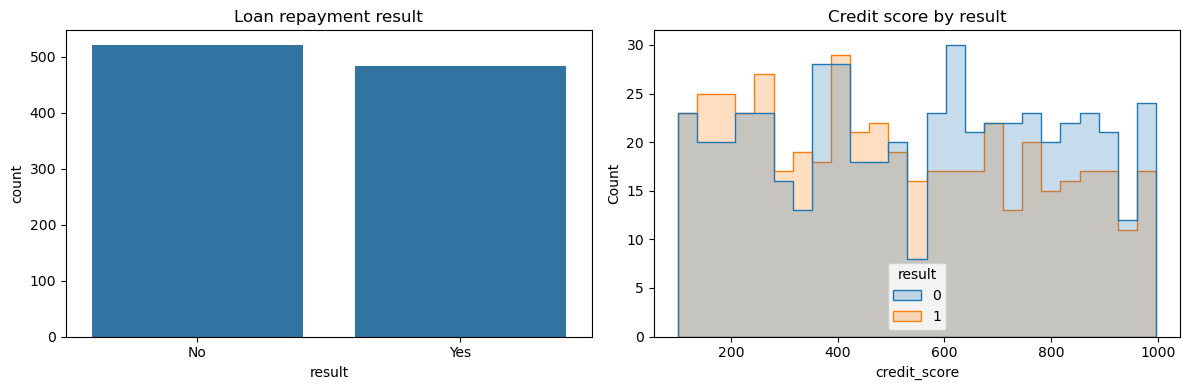

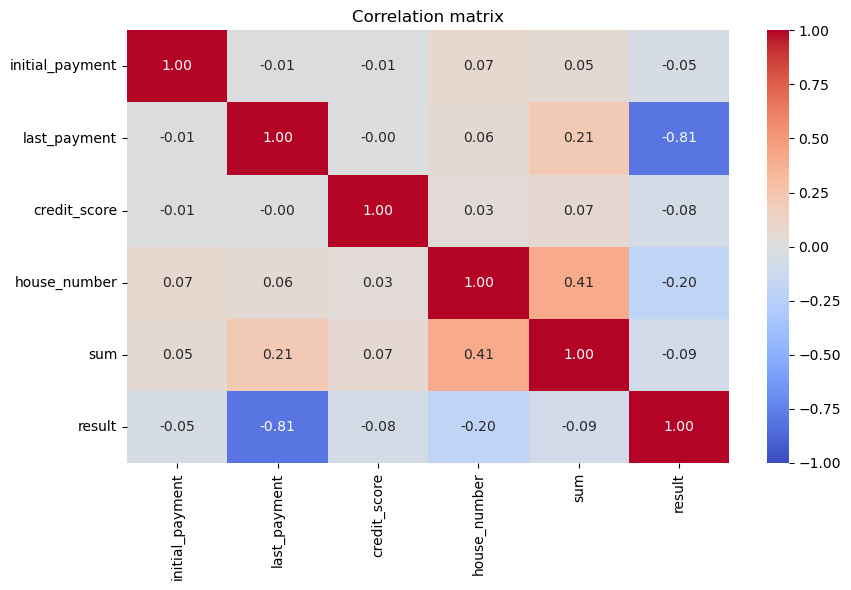

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="result", ax=axes[0])
axes[0].set_title("Loan repayment result")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No", "Yes"])

sns.histplot(
    data=df,
    x="credit_score",
    hue="result",
    bins=25,
    element="step",
    ax=axes[1]
)
axes[1].set_title("Credit score by result")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [6]:
X = df.drop(columns=["result"])
y = df["result"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (753, 5)
Testing: (251, 5)


In [7]:
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=0
)

model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

display(pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
}).head(10))

,Actual,Predicted
0,1,1
1,0,0
2,0,0
3,0,0
4,1,1
5,0,0
6,1,1
7,1,1
8,0,0
9,1,1


Training accuracy: 100.00%
Test accuracy: 99.60%

Classification report:
              precision    recall  f1-score   support

          No      0.992     1.000     0.996       130
         Yes      1.000     0.992     0.996       121

    accuracy                          0.996       251
   macro avg      0.996     0.996     0.996       251
weighted avg      0.996     0.996     0.996       251

ROC AUC: 0.996


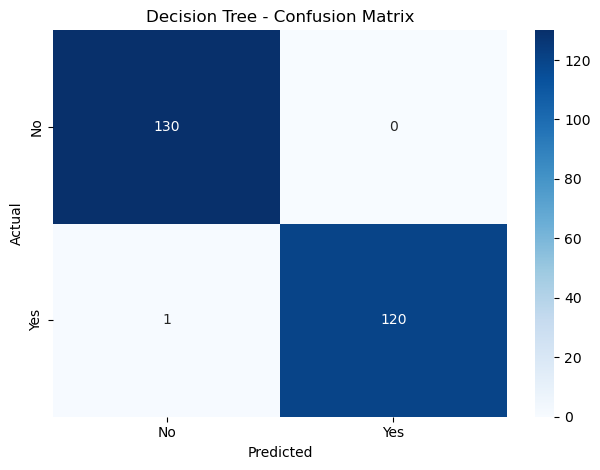

TN = 130, FP = 0, FN = 1, TP = 120


In [8]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No", "Yes"],
    digits=3,
    zero_division=0
))

y_probability = model.predict_proba(X_test_scaled)[:, 1]
print(f"ROC AUC: {roc_auc_score(y_test, y_probability):.3f}")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

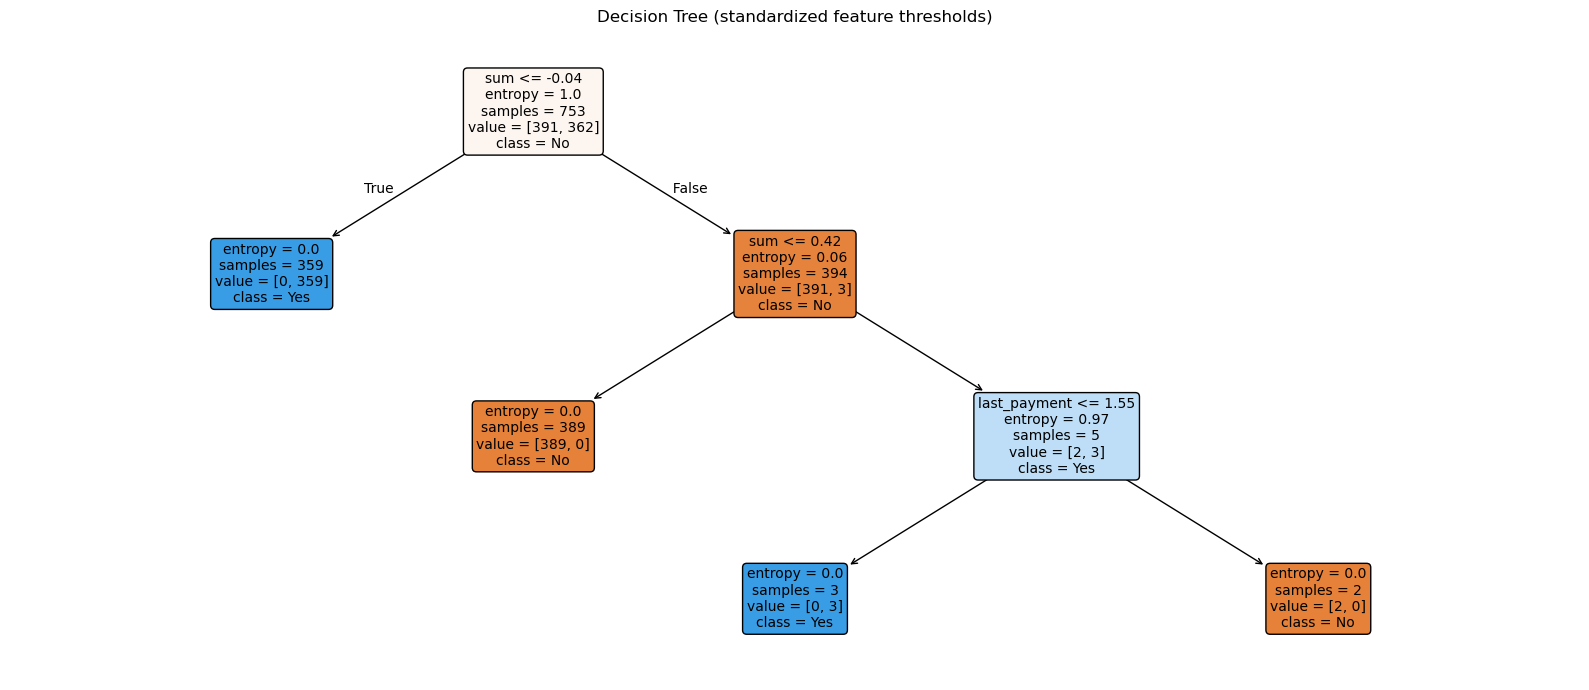

Feature importance:


sum                0.993546
last_payment       0.006454
initial_payment    0.000000
credit_score       0.000000
house_number       0.000000
dtype: float64

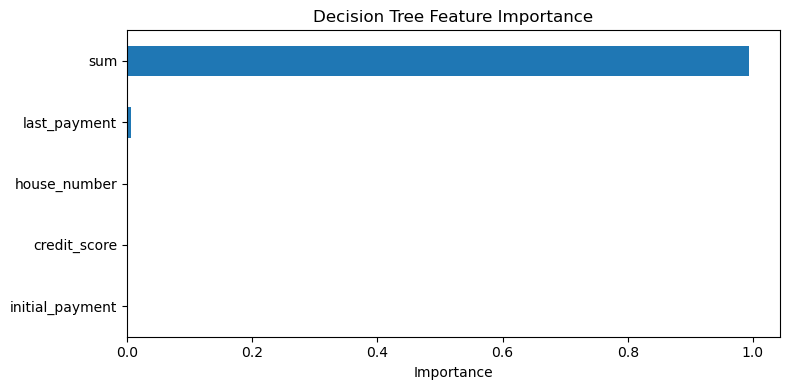

In [9]:
plt.figure(figsize=(16, 7))

plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    precision=2,
    fontsize=10
)

plt.title("Decision Tree (standardized feature thresholds)")
plt.tight_layout()
plt.show()

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature importance:")
display(importance)

importance.sort_values().plot.barh(figsize=(8, 4))
plt.xlabel("Importance")
plt.title("Decision Tree Feature Importance")
plt.tight_layout()
plt.show()

## Conclusion

The dataset contains 1,004 records with no missing values or duplicate rows.
I encoded the result column and split the data into 75% training and 25%
testing. StandardScaler was fitted only on the training data.

The Decision Tree used entropy to choose its splits. It correctly classified
250 of the 251 test records, giving 99.60% accuracy. The confusion matrix
shows 130 true negatives, 120 true positives, no false positives, and one
false negative.

The sum column accounted for most of the model's feature importance.
The high test score shows that this dataset was easy for the tree to
separate, but it does not establish how well the model would perform
on new real-world loan applications.